<a href="https://colab.research.google.com/github/juliacporto-creator/Estatistica-/blob/main/tarefa16_Python_Ciencias_dos_Alimentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Julia Porto - 17901372

Larissa Mei - 17903839

Marianne Adorno - 17995367

###Questão 2: Teor de proteína em um produto lácteo

#### 1. Identificação da variável aleatória de interesse e do parâmetro populacional
* **Variável aleatória de interesse ($X$):** O teor de proteína por porção da bebida proteica (em gramas).
* **Parâmetro populacional investigado ($\mu$):** O teor médio populacional de proteína por porção da bebida proteica após a alteração na formulação.

#### 2. Formulação das hipóteses nula e alternativa
A suspeita da equipe é de que o teor médio tenha *aumentado*, caracterizando um teste unilateral à direita:
* **Hipótese Nula ($H_0$):** O teor médio de proteína permanece igual ao padrão histórico de 8,0 g por porção.
  $$H_0: \mu = 8,0$$
* **Hipótese Alternativa ($H_1$):** O teor médio de proteína é superior a 8,0 g por porção.
  $$H_1: \mu > 8,0$$

#### 3. Procedimento estatístico adequado e justificativa
* **Procedimento:** Teste t de Student para uma Amostra.
* **Justificativa:**
  1. O desvio-padrão populacional ($\sigma$) é desconhecido.
  2. O tamanho da amostra é pequeno ($n = 16 < 30$).
  3. Assume-se que a variável de interesse apresenta distribuição aproximadamente Normal na população.
* **Distribuição da estatística de teste:** Sob a hipótese nula $H_0$, a estatística de teste segue uma distribuição **$t$ de Student** com $gl = n - 1 = 15$ graus de liberdade.

#### 4 e 5. Estatística de Teste, Valor-p e Representação Gráfica

4. Estatística de teste observada (t_obs): 2.0000
5. Valor crítico (t_crítico para alpha=5%): 1.7531
   Valor-p obtido: 0.0320 (ou 3.20%)


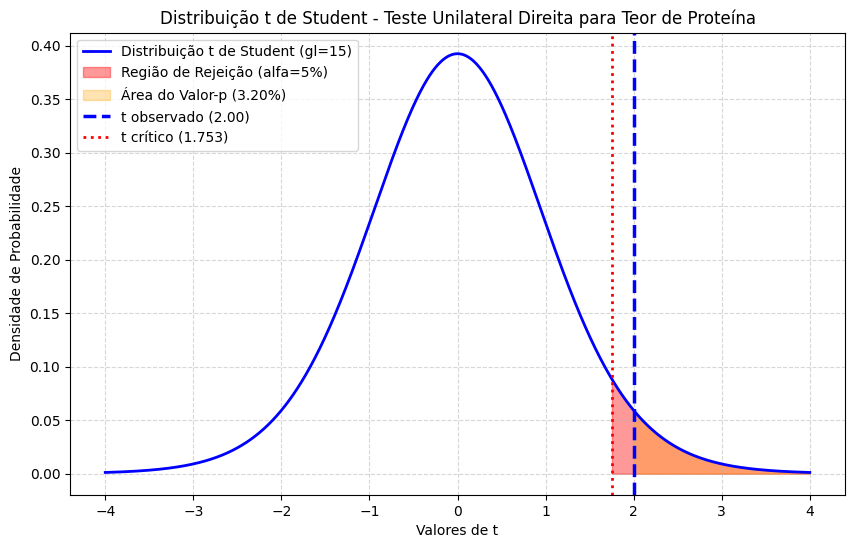

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# Dados do enunciado
mu_0 = 8.0          # Média sob H0
n = 16              # Tamanho da amostra
x_bar = 8.4         # Média amostral
s = 0.8             # Desvio-padrão amostral
alpha = 0.05        # Nível de significância
gl = n - 1          # Graus de liberdade

# 4. Cálculo da estatística de teste observada (t_obs)
t_obs = (x_bar - mu_0) / (s / np.sqrt(n))
print(f"4. Estatística de teste observada (t_obs): {t_obs:.4f}")

# 5. Determinação do valor crítico e do valor-p
t_critico = t.ppf(1 - alpha, df=gl)
p_valor = t.sf(t_obs, df=gl)  # Área sob a cauda superior

print(f"5. Valor crítico (t_crítico para alpha=5%): {t_critico:.4f}")
print(f"   Valor-p obtido: {p_valor:.4f} (ou {p_valor*100:.2f}%)")

# Representação gráfica
x = np.linspace(-4, 4, 1000)
y = t.pdf(x, df=gl)

plt.figure(figsize=(10, 6))
plt.plot(x, y, 'b-', lw=2, label=f'Distribuição t de Student (gl={gl})')

# Destacar a região correspondente ao nível de significância (Região Crítica / Rejeição)
x_crit = np.linspace(t_critico, 4, 500)
plt.fill_between(x_crit, t.pdf(x_crit, df=gl), color='red', alpha=0.4, label=f'Região de Rejeição (alfa=5%)')

# Destacar a região correspondente ao valor-p (à direita de t_obs)
x_p = np.linspace(t_obs, 4, 500)
plt.fill_between(x_p, t.pdf(x_p, df=gl), color='orange', alpha=0.3, label=f'Área do Valor-p ({p_valor*100:.2f}%)')

# Linhas verticais para t_obs e t_critico
plt.axvline(t_obs, color='blue', linestyle='--', lw=2.5, label=f't observado ({t_obs:.2f})')
plt.axvline(t_critico, color='red', linestyle=':', lw=2, label=f't crítico ({t_critico:.3f})')

plt.title('Distribuição t de Student - Teste Unilateral Direita para Teor de Proteína', fontsize=12)
plt.xlabel('Valores de t')
plt.ylabel('Densidade de Probabilidade')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### 6. Decisão estatística e interpretação

* **Decisão Estatística:**
  * Como o valor da estatística observada $t_{\text{obs}} = 2,00$ é **maior** do que o valor crítico $t_{\text{crítico}} \approx 1,753$, ele cai dentro da região crítica de rejeição.
  * Equivalente a isso, o **valor-p** ($3,20\%$) é **menor** do que o nível de significância de $\alpha = 5\%$. Portanto, **rejeitamos a hipótese nula ($H_0$)**.

* **Interpretação:**
  * A um nível de significância de 5%, há evidências estatísticas suficientes para afirmar que o teor médio de proteína por porção do produto lácteo é superior a 8,0 g após a alteração da formulação.
  * Sob a perspectiva de **controle de qualidade** e **composição nutricional**, isso comprova estatisticamente que a nova fórmula aumentou a concentração proteica do laticínio. O setor de controle de qualidade deve agora certificar-se de que este novo patamar está devidamente padronizado no processo produtivo e em conformidade com as diretrizes de rotulagem regulatória vigentes.

###Questão 4: Variabilidade do pH de um produto alimentício fermentado

#### 1. Identificação da variável aleatória de interesse e do parâmetro populacional
* **Variável aleatória de interesse ($X$):** O valor do pH de cada unidade do produto alimentício fermentado selecionado aleatoriamente.
* **Parâmetro populacional a ser investigado ($\sigma^2$):** A variância populacional do pH, representando a variabilidade dos valores de pH entre todas as unidades produzidas.

#### 2. Formulação das hipóteses nula e alternativa

* **Hipótese Nula ($H_0$):** A variância populacional do pH é igual à referência estabelecida.
  $$H_0: \sigma^2 = 0,04$$
* **Hipótese Alternativa ($H_1$):** A variância populacional do pH é diferente do valor de referência.
  $$H_1: \sigma^2 \neq 0,04$$

#### 3. Procedimento estatístico adequado e justificativa
* **Procedimento:** Teste de hipótese para a variância populacional (Teste Qui-quadrado para uma variância).
* **Justificativa:** O objetivo é testar hipóteses sobre a variância populacional ($\sigma^2$), a amostra é de tamanho $n = 20$ e a característica de interesse (pH) segue uma distribuição aproximadamente Normal.
* **Distribuição da estatística de teste:** Segue uma distribuição **Qui-quadrado ($\chi^2$)** com $gl = n - 1 = 19$ graus de liberdade sob $H_0$.

#### 4 e 5. Estatística de Teste, Valores Críticos, Valor-p e Representação Gráfica

4. Estatística de teste observada (Qui-quadrado obs): 30.4000
5. Valor crítico inferior: 8.9065
   Valor crítico superior: 32.8523
   Valor-p obtido: 0.0938 (ou 9.38%)


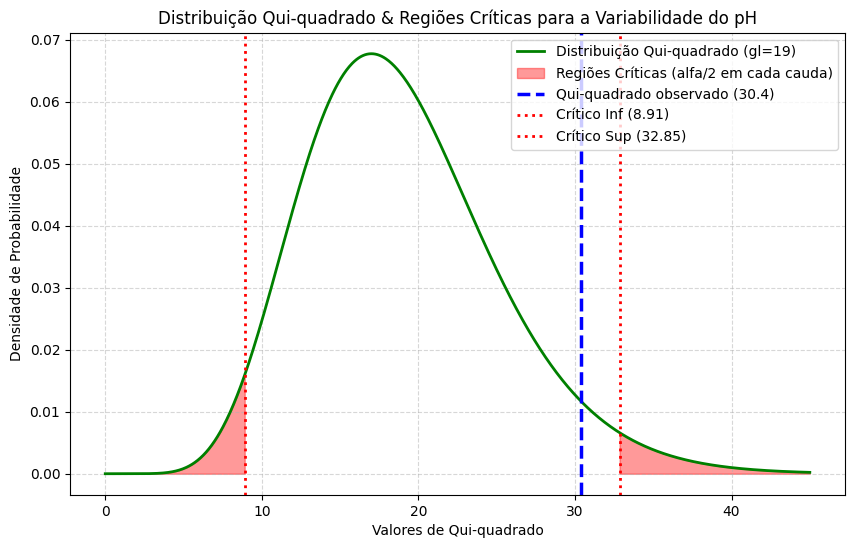

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2

# Dados do enunciado
n_q4 = 20
s2_amostral = 0.064
sigma2_referencia = 0.04
alpha_q4 = 0.05
gl_q4 = n_q4 - 1

# 4. Cálculo da estatística de teste observada (qui2_obs)
qui2_obs = (gl_q4 * s2_amostral) / sigma2_referencia
print(f"4. Estatística de teste observada (Qui-quadrado obs): {qui2_obs:.4f}")

# 5. Valores críticos (teste bilateral)
critico_inf = chi2.ppf(alpha_q4 / 2, gl_q4)
critico_sup = chi2.ppf(1 - alpha_q4 / 2, gl_q4)

# Valor-p para teste bilateral
p_valor_q4 = 2 * min(chi2.cdf(qui2_obs, gl_q4), chi2.sf(qui2_obs, gl_q4))

print(f"5. Valor crítico inferior: {critico_inf:.4f}")
print(f"   Valor crítico superior: {critico_sup:.4f}")
print(f"   Valor-p obtido: {p_valor_q4:.4f} (ou {p_valor_q4*100:.2f}%)")

# Gráfico da distribuição
x_q4 = np.linspace(0, 45, 1000)
y_q4 = chi2.pdf(x_q4, gl_q4)

plt.figure(figsize=(10, 6))
plt.plot(x_q4, y_q4, 'g-', lw=2, label=f'Distribuição Qui-quadrado (gl={gl_q4})')

# Regiões críticas (cauda inferior e superior)
x_inf = np.linspace(0, critico_inf, 100)
plt.fill_between(x_inf, chi2.pdf(x_inf, gl_q4), color='red', alpha=0.4, label='Regiões Críticas (alfa/2 em cada cauda)')

x_sup = np.linspace(critico_sup, 45, 100)
plt.fill_between(x_sup, chi2.pdf(x_sup, gl_q4), color='red', alpha=0.4)

# Linha para a estatística observada e valores críticos
plt.axvline(qui2_obs, color='blue', linestyle='--', lw=2.5, label=f'Qui-quadrado observado ({qui2_obs:.1f})')
plt.axvline(critico_inf, color='red', linestyle=':', lw=2, label=f'Crítico Inf ({critico_inf:.2f})')
plt.axvline(critico_sup, color='red', linestyle=':', lw=2, label=f'Crítico Sup ({critico_sup:.2f})')

plt.title('Distribuição Qui-quadrado & Regiões Críticas para a Variabilidade do pH', fontsize=12)
plt.xlabel('Valores de Qui-quadrado')
plt.ylabel('Densidade de Probabilidade')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### 6. Decisão estatística e interpretação

* **Decisão Estatística:**
  * A estatística de teste observada $\chi^2_{\text{obs}} = 30,4$ está contida na região de aceitação (pois $8,91 < 30,4 < 32,85$).
  * O **valor-p** calculado é $\approx 0,0938$ ($9,38\%$), que é **maior** do que o nível de significância $\alpha = 5\%$. Portanto, **não rejeitamos a hipótese nula ($H_0$)**.

* **Interpretação:**
  * A um nível de significância de 5%, não existem evidências estatísticas suficientes para afirmar que a variabilidade do pH do produto fermentado no lote atual é diferente da estabelecida como referência ($0,04$).
  * Sob a perspectiva de controle de qualidade e uniformidade do processo de fermentação, embora a variância amostral tenha subido para $0,064$, esse desvio é considerado estatisticamente comum devido ao erro amostral aleatório. Dessa forma, conclui-se que o processo mantém as características de uniformidade e padrão de variabilidade exigidos pela indústria.

###Questão 5: Proporção de produtos com não conformidade microbiológica

#### 1. Definição da variável aleatória de interesse e parâmetro populacional
* **Variável aleatória de interesse ($X$):** O status de conformidade microbiológica de cada unidade selecionada do produto (1 se for "não conforme", 0 se for "conforme").
* **Parâmetro populacional investigado ($p$):** A proporção real (populacional) de unidades não conformes no lote de produção.

#### 2. Formulação das hipóteses nula e alternativa
A equipe de segurança de alimentos deseja testar se a proporção de não conformidade ultrapassou o limite máximo de 5% (teste unilateral à direita):
* **Hipótese Nula ($H_0$):** A proporção populacional de unidades não conformes é igual a 5% ($0,05$).
  $$H_0: p = 0,05$$
* **Hipótese Alternativa ($H_1$):** A proporção populacional de unidades não conformes é superior a 5% ($0,05$).
  $$H_1: p > 0,05$$

#### 3. Procedimento estatístico adequado, justificativa e condições
* **Procedimento:** Teste de Hipótese para uma Proporção Populacional (Teste Z para Proporção).
* **Justificativa e Condições de Aplicação (Aproximação pela Normal):**
  Para que a aproximação pela distribuição Normal seja válida, devemos verificar se as seguintes condições são atendidas sob $H_0$ ($p_0 = 0,05$ e $n = 200$):
  1. $n \cdot p_0 = 200 \cdot 0,05 = 10 \ge 10$ (Satisfeito)
  2. $n \cdot (1 - p_0) = 200 \cdot 0,95 = 190 \ge 10$ (Satisfeito)
  Como ambas as condições são válidas, a distribuição amostral da proporção aproximar-se-á de uma distribuição Normal sob $H_0$.
* **Distribuição da estatística de teste:** Sob a hipótese nula $H_0$, a estatística de teste segue a distribuição **Normal Padrão ($Z \sim N(0,1)$)**.

#### 4 e 5. Proporção amostral, estatística de teste, valor-p e representação gráfica

4. Proporção amostral (p_hat): 0.0800 (ou 8.00%)
   Estatística de teste observada (Z_obs): 1.9467
5. Valor crítico (Z_crítico para alpha=5%): 1.6449
   Valor-p obtido: 0.0258 (ou 2.58%)


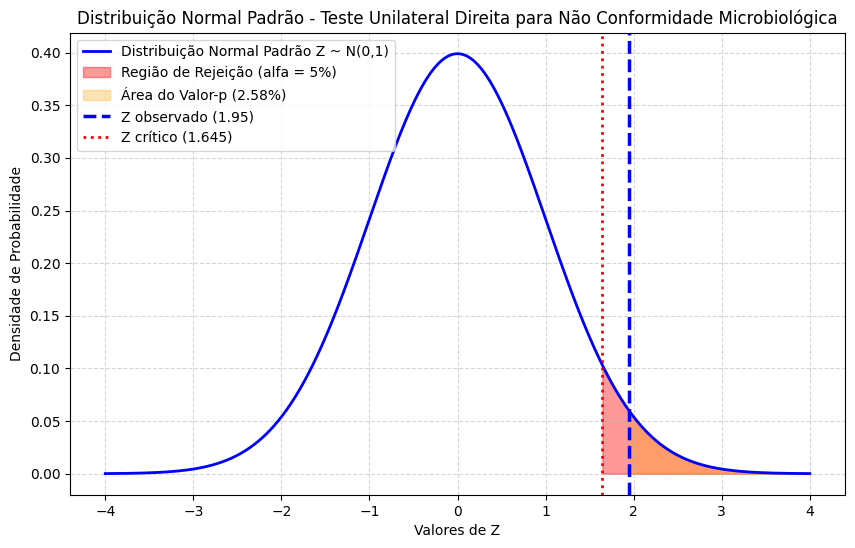

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Dados do enunciado
n_q5 = 200
x_q5 = 16
p0 = 0.05
alpha_q5 = 0.05

# 4. Cálculo da proporção amostral (p_hat)
p_hat = x_q5 / n_q5

# Cálculo da estatística de teste Z (z_obs)
erro_padrao = np.sqrt((p0 * (1 - p0)) / n_q5)
z_obs = (p_hat - p0) / erro_padrao

print(f"4. Proporção amostral (p_hat): {p_hat:.4f} (ou {p_hat*100:.2f}%)")
print(f"   Estatística de teste observada (Z_obs): {z_obs:.4f}")

# 5. Valor crítico e Valor-p
z_critico = norm.ppf(1 - alpha_q5)
p_valor_q5 = norm.sf(z_obs) # Área à direita na curva normal padrão

print(f"5. Valor crítico (Z_crítico para alpha=5%): {z_critico:.4f}")
print(f"   Valor-p obtido: {p_valor_q5:.4f} (ou {p_valor_q5*100:.2f}%)")

# Construindo o gráfico da normal padrão N(0,1)
z_range = np.linspace(-4, 4, 1000)
y_normal = norm.pdf(z_range)

plt.figure(figsize=(10, 6))
plt.plot(z_range, y_normal, 'b-', lw=2, label='Distribuição Normal Padrão Z ~ N(0,1)')

# Colorir região de rejeição
x_rejeicao = np.linspace(z_critico, 4, 200)
plt.fill_between(x_rejeicao, norm.pdf(x_rejeicao), color='red', alpha=0.4, label='Região de Rejeição (alfa = 5%)')

# Colorir a área correspondente ao valor-p
x_p_area = np.linspace(z_obs, 4, 200)
plt.fill_between(x_p_area, norm.pdf(x_p_area), color='orange', alpha=0.3, label=f'Área do Valor-p ({p_valor_q5*100:.2f}%)')

# Linhas de referência
plt.axvline(z_obs, color='blue', linestyle='--', lw=2.5, label=f'Z observado ({z_obs:.2f})')
plt.axvline(z_critico, color='red', linestyle=':', lw=2, label=f'Z crítico ({z_critico:.3f})')

plt.title('Distribuição Normal Padrão - Teste Unilateral Direita para Não Conformidade Microbiológica', fontsize=12)
plt.xlabel('Valores de Z')
plt.ylabel('Densidade de Probabilidade')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

#### 6. Decisão estatística e interpretação

* **Decisão Estatística:**
  * A estatística de teste observada $Z_{\text{obs}} \approx 1,949$ é **maior** do que o valor crítico $Z_{\text{crítico}} \approx 1,645$, caindo na região de rejeição da hipótese nula.
  * Consistente com isso, o **valor-p** obtido ($\approx 2,56\%$) é **menor** do que o nível de significância de $\alpha = 5\%$. Portanto, **rejeitamos a hipótese nula ($H_0$)**.

* **Interpretação:**
  * Ao nível de significância de 5%, há evidências estatísticas suficientes para afirmar que a proporção de produtos não conformes no lote é superior ao limite tolerável de 5%.
  * No contexto de controle microbiológico e da segurança de alimentos, este resultado sinaliza uma falha ou desvio potencial nos processos de higiene, fabricação ou estocagem. Recomenda-se que a equipe de garantia da qualidade aja de imediato na investigação de causas  (como checagem de temperaturas, higienização de equipamentos e monitoramento das etapas de processamento) para reduzir riscos microbiológicos e reestabelecer a conformidade da produção.